# Prototype D: what happened next
**Question:** Once a town pauses data centers, does the pause get lifted, extended, or made permanent?

**Data:** Moratorium Nation `enacted_status` (closed vocabulary from the dataset author) and `current_end_date` (current fixed end date after extensions), adopted data center moratoria only.

Status meanings (from the codebook): **active** still in effect; **extended** term lengthened; **replaced** replaced by a permanent ordinance; **expired** term elapsed; **rescinded** repealed.

Caveat carried onto the page: most of these pauses were adopted in 2026, so most have not reached their end yet. This is an early read, not a final tally.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name in ("data", "jppolizzi", "pnidadavolu") else Path.cwd()
sys.path[:0] = [str(ROOT / ".pylibs"), str(ROOT / "scripts")]
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = ROOT / "data" / "clean"
TODAY = pd.Timestamp("2026-11-15")  # snapshot date for "still in effect" and "upcoming"

m = pd.read_csv(CLEAN / "moratoria_local.csv", parse_dates=["date_enacted", "current_end_date"], dtype={"county_geoid": str})
a = m[m.adopted].copy()   # drop proposals (pending), defeated proposals (rejected) and unknown status

# Palette: categorical slots in fixed order (validated: CVD and normal-vision pass; aqua/yellow need direct labels).
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a9a89f"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})
order = ["active", "extended", "replaced", "expired", "rescinded"]
st = a["enacted_status"].value_counts().reindex(order).fillna(0).astype(int)
display(st.to_frame("adopted moratoria").T)
changed = st.drop("active").sum()
kept = st[["extended", "replaced"]].sum()
lifted = st[["expired", "rescinded"]].sum()
print(f"{changed} have a status other than active: {kept} ({kept / changed:.0%}) extended or made permanent, {lifted} ({lifted / changed:.0%}) expired or repealed")

enacted_status,active,extended,replaced,expired,rescinded
adopted moratoria,812,134,50,30,10


224 have a status other than active: 184 (82%) extended or made permanent, 40 (18%) expired or repealed


## Upcoming end dates (pauses still in effect)

In [2]:
f = a[a.in_force]
fixed = f[f.current_end_date.notna()]
up = fixed[fixed.current_end_date >= TODAY]
past = fixed[fixed.current_end_date < TODAY]
print(f"{len(f)} in force; {len(fixed)} have a fixed end date ({len(up)} upcoming, {len(past)} already past but not yet updated)")
print("No fixed end date:", f[f.current_end_date.isna()]["duration_kind"].value_counts().to_dict())
uq = up.groupby(up.current_end_date.dt.to_period("Q")).size()
display(uq.to_frame("ending").T)
by27 = int((up.current_end_date <= "2027-12-31").sum())
print(f"{by27} of {len(up)} upcoming end dates fall by the end of 2027")

946 in force; 170 have a fixed end date (170 upcoming, 0 already past but not yet updated)
No fixed end date: {'calendar_term': 489, 'fixed_days': 146, 'unknown': 80, 'until_date': 33, 'until_event': 21, 'indefinite': 7}


current_end_date,2026Q4,2027Q1,2027Q2,2027Q3,2027Q4,2028Q1,2028Q2,2028Q3,2028Q4,2029Q1,2029Q3
ending,31,41,39,35,7,3,2,8,2,1,1


153 of 170 upcoming end dates fall by the end of 2027


## Static figure for the proposal (saved as an image)

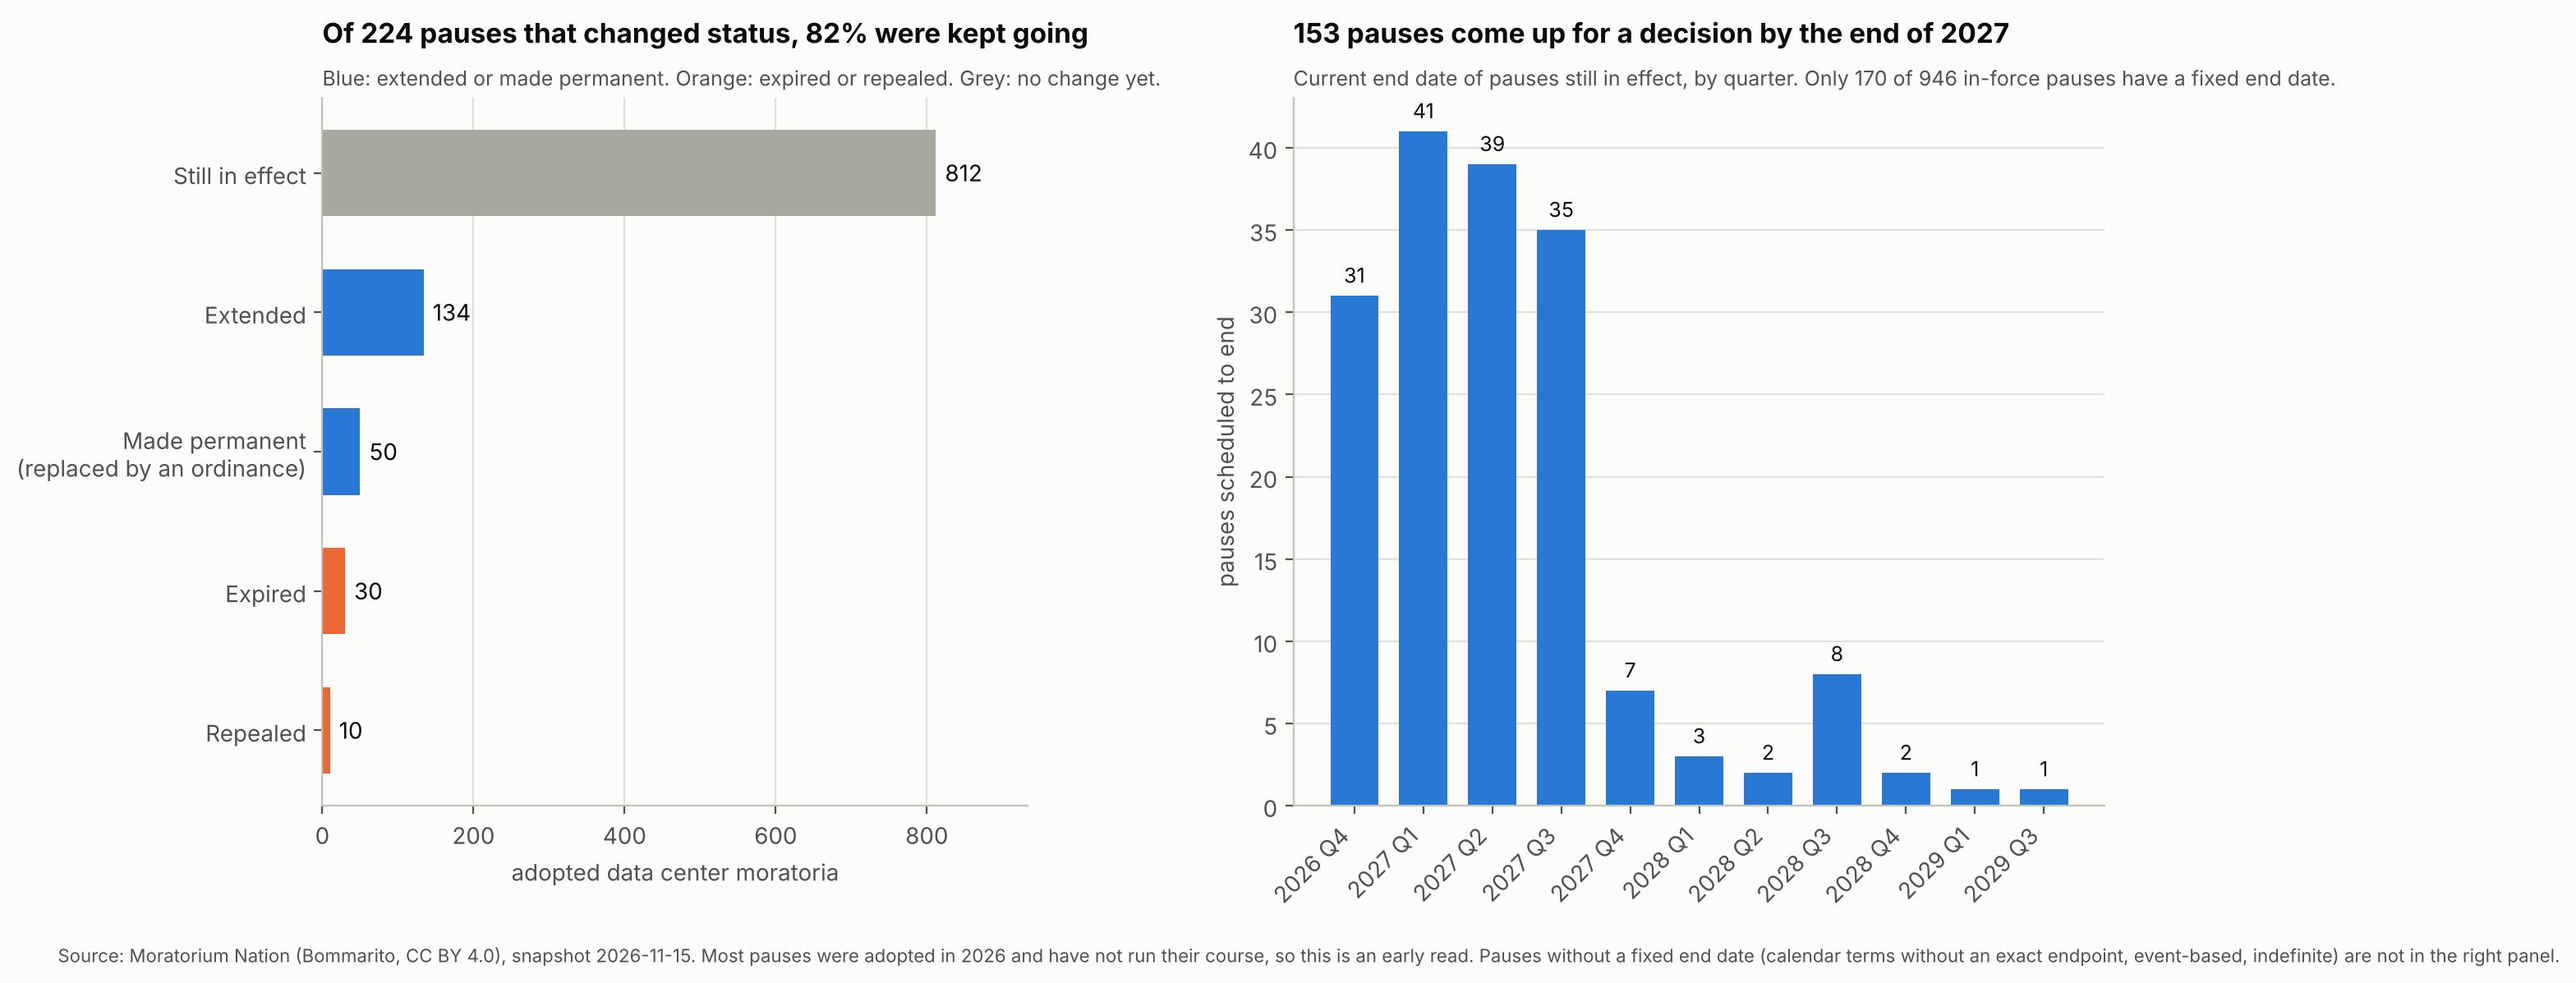

In [3]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1, 1.15], wspace=0.35))

LBL = {"active": "Still in effect", "extended": "Extended", "replaced": "Made permanent\n(replaced by an ordinance)",
       "expired": "Expired", "rescinded": "Repealed"}
COL = {"active": NEUTRAL, "extended": BLUE, "replaced": BLUE, "expired": ORANGE, "rescinded": ORANGE}
y = np.arange(len(order))[::-1]
ax.barh(y, st.values, color=[COL[k] for k in order], height=0.62)
for yi, v in zip(y, st.values):
    ax.text(v + 12, yi, f"{v:,}", va="center", color=INK, fontsize=10)
ax.set_yticks(y, [LBL[k] for k in order]); ax.set_xlim(0, st.max() * 1.15)
ax.set_xlabel("adopted data center moratoria")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.set_title(f"Of {changed} pauses that changed status, {kept / changed:.0%} were kept going", loc="left", fontsize=12, fontweight="bold", pad=24)
ax.text(0, 1.01, "Blue: extended or made permanent. Orange: expired or repealed. Grey: no change yet.", transform=ax.transAxes, color=INK2, fontsize=9, va="bottom")

lab = [str(p).replace("Q", " Q") for p in uq.index]
bx.bar(np.arange(len(uq)), uq.values, color=BLUE, width=0.7)
for i, v in enumerate(uq.values):
    bx.text(i, v + 0.8, str(v), ha="center", color=INK, fontsize=9)
bx.set_xticks(np.arange(len(uq)), lab, rotation=45, ha="right")
bx.set_ylabel("pauses scheduled to end")
bx.grid(axis="y", color=GRID, lw=0.8); bx.set_axisbelow(True)
for s in ["top", "right"]: bx.spines[s].set_visible(False)
bx.set_title(f"{by27} pauses come up for a decision by the end of 2027", loc="left", fontsize=12, fontweight="bold", pad=24)
bx.text(0, 1.01, f"Current end date of pauses still in effect, by quarter. Only {len(fixed)} of {len(f)} in-force pauses have a fixed end date.",
        transform=bx.transAxes, color=INK2, fontsize=9, va="bottom")
fig.text(0.01, -0.06, "Source: Moratorium Nation (Bommarito, CC BY 4.0), snapshot 2026-11-15. Most pauses were adopted in 2026 and have not run their course, "
         "so this is an early read. Pauses without a fixed end date (calendar terms without an exact endpoint, event-based, indefinite) are not in the right panel.",
         fontsize=8, color=INK2)
fig.savefig(ROOT / "images" / "prototype_d_what_next.png", dpi=160, bbox_inches="tight")
plt.show()

Next for the D3 version:
- Guess first: "What share of paused towns lifted the pause?" The reader drags a slider, then the real split animates in.
- Hover a bar to list the towns in it; click one to jump to it on the Prototype C map.
- Re-run when the dataset updates, since many pauses end in 2027.